# 04d – Synthèse des données socio-économiques

Je réunis les 3 fichiers propres (04a CSP, 04b unités urbaines, 04c Ameli) et je les montre sur des cartes pour voir où se trouvent les différences entre départements.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 1. Réunir les 3 fichiers

On réunit les tableaux grâce à la colonne code_dep.

In [2]:
#Lire les 3 fichiers de synthèse de 04a/b/c (Data processed)
csp = pd.read_csv('../data/processed/insee_csp_2022_propre.csv', dtype={'code_dep': str})
uu = pd.read_csv('../data/processed/insee_urbain_2017_propre.csv', dtype={'code_dep': str})
ameli = pd.read_csv('../data/processed/ameli_2024_propre.csv', dtype={'code_dep': str})

# merge réunit 2 tableaux à la fois
# on='code_dep': on rassemble les lignes avec le même code de département

#on rassemble les données ameli avec les données de pourcentage urbain (pct_urbain) de uu
socio = pd.merge(ameli, uu[['code_dep', 'pct_urbain']], on='code_dep')

# On enlève nom_dep et est_drom, déjà présents dans socio et on garde le reste des données csp
socio = pd.merge(socio, csp.drop(columns=['nom_dep', 'est_drom']), on='code_dep')

print(socio.shape)
socio.head()

(100, 25)


,code_dep,nom_dep,est_drom,population,nb_generalistes,nb_pediatres,nb_pneumologues,nb_allergologues,nb_kines,nb_sos,...,sos_present,pct_urbain,pct_agriculteurs,pct_artisans,pct_cadres,pct_prof_inter,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite
0,01,Ain,False,688626,368,9,7,2,533,0,...,False,67.0,0.6,4.1,10.0,16.6,15.5,14.2,26.0,12.9
1,02,Aisne,False,518817,311,9,16,4,294,1,...,True,53.2,1.0,2.7,4.8,12.4,16.0,16.5,30.0,16.6
2,03,Allier,False,332599,221,5,5,1,351,0,...,False,58.3,1.6,3.3,4.9,11.3,15.2,13.0,37.6,13.2
3,04,Alpes-Hte-Provence,False,169806,152,10,1,1,241,1,...,True,61.9,1.5,5.4,6.6,13.3,14.4,10.5,34.9,13.5
4,05,Hautes-Alpes,False,142006,178,0,0,0,383,0,...,False,59.5,1.6,5.4,5.9,15.2,16.2,9.9,34.6,11.2


On obtient 100 départements (Mayotte n'est pas dans le fichier CSP) et 25 colonnes d'informations pour chacun.

## 2. Cartes

Nécessite la bibliothèque geopandas pour dessiner la carte. Le fond de carte est obtenu grâce à geojson (lien)

(96, 3)
  code                      nom  \
0   01                      Ain   
1   02                    Aisne   
2   03                   Allier   
3   04  Alpes-de-Haute-Provence   
4   05             Hautes-Alpes   

                                            geometry  
0  POLYGON ((4.78021 46.17668, 4.79458 46.21832, ...  
1  POLYGON ((4.04797 49.40564, 4.03991 49.3974, 4...  
2  POLYGON ((3.03207 46.79491, 3.04907 46.75808, ...  
3  POLYGON ((5.67604 44.19143, 5.69209 44.18648, ...  
4  POLYGON ((6.26057 45.12685, 6.29922 45.10855, ...  
  code_dep                      nom             nom_dep
0       01                      Ain                 Ain
1       02                    Aisne               Aisne
2       03                   Allier              Allier
3       04  Alpes-de-Haute-Provence  Alpes-Hte-Provence
4       05             Hautes-Alpes        Hautes-Alpes
5       06          Alpes-Maritimes     Alpes-Maritimes
6       07                  Ardèche             Ardèche
7  

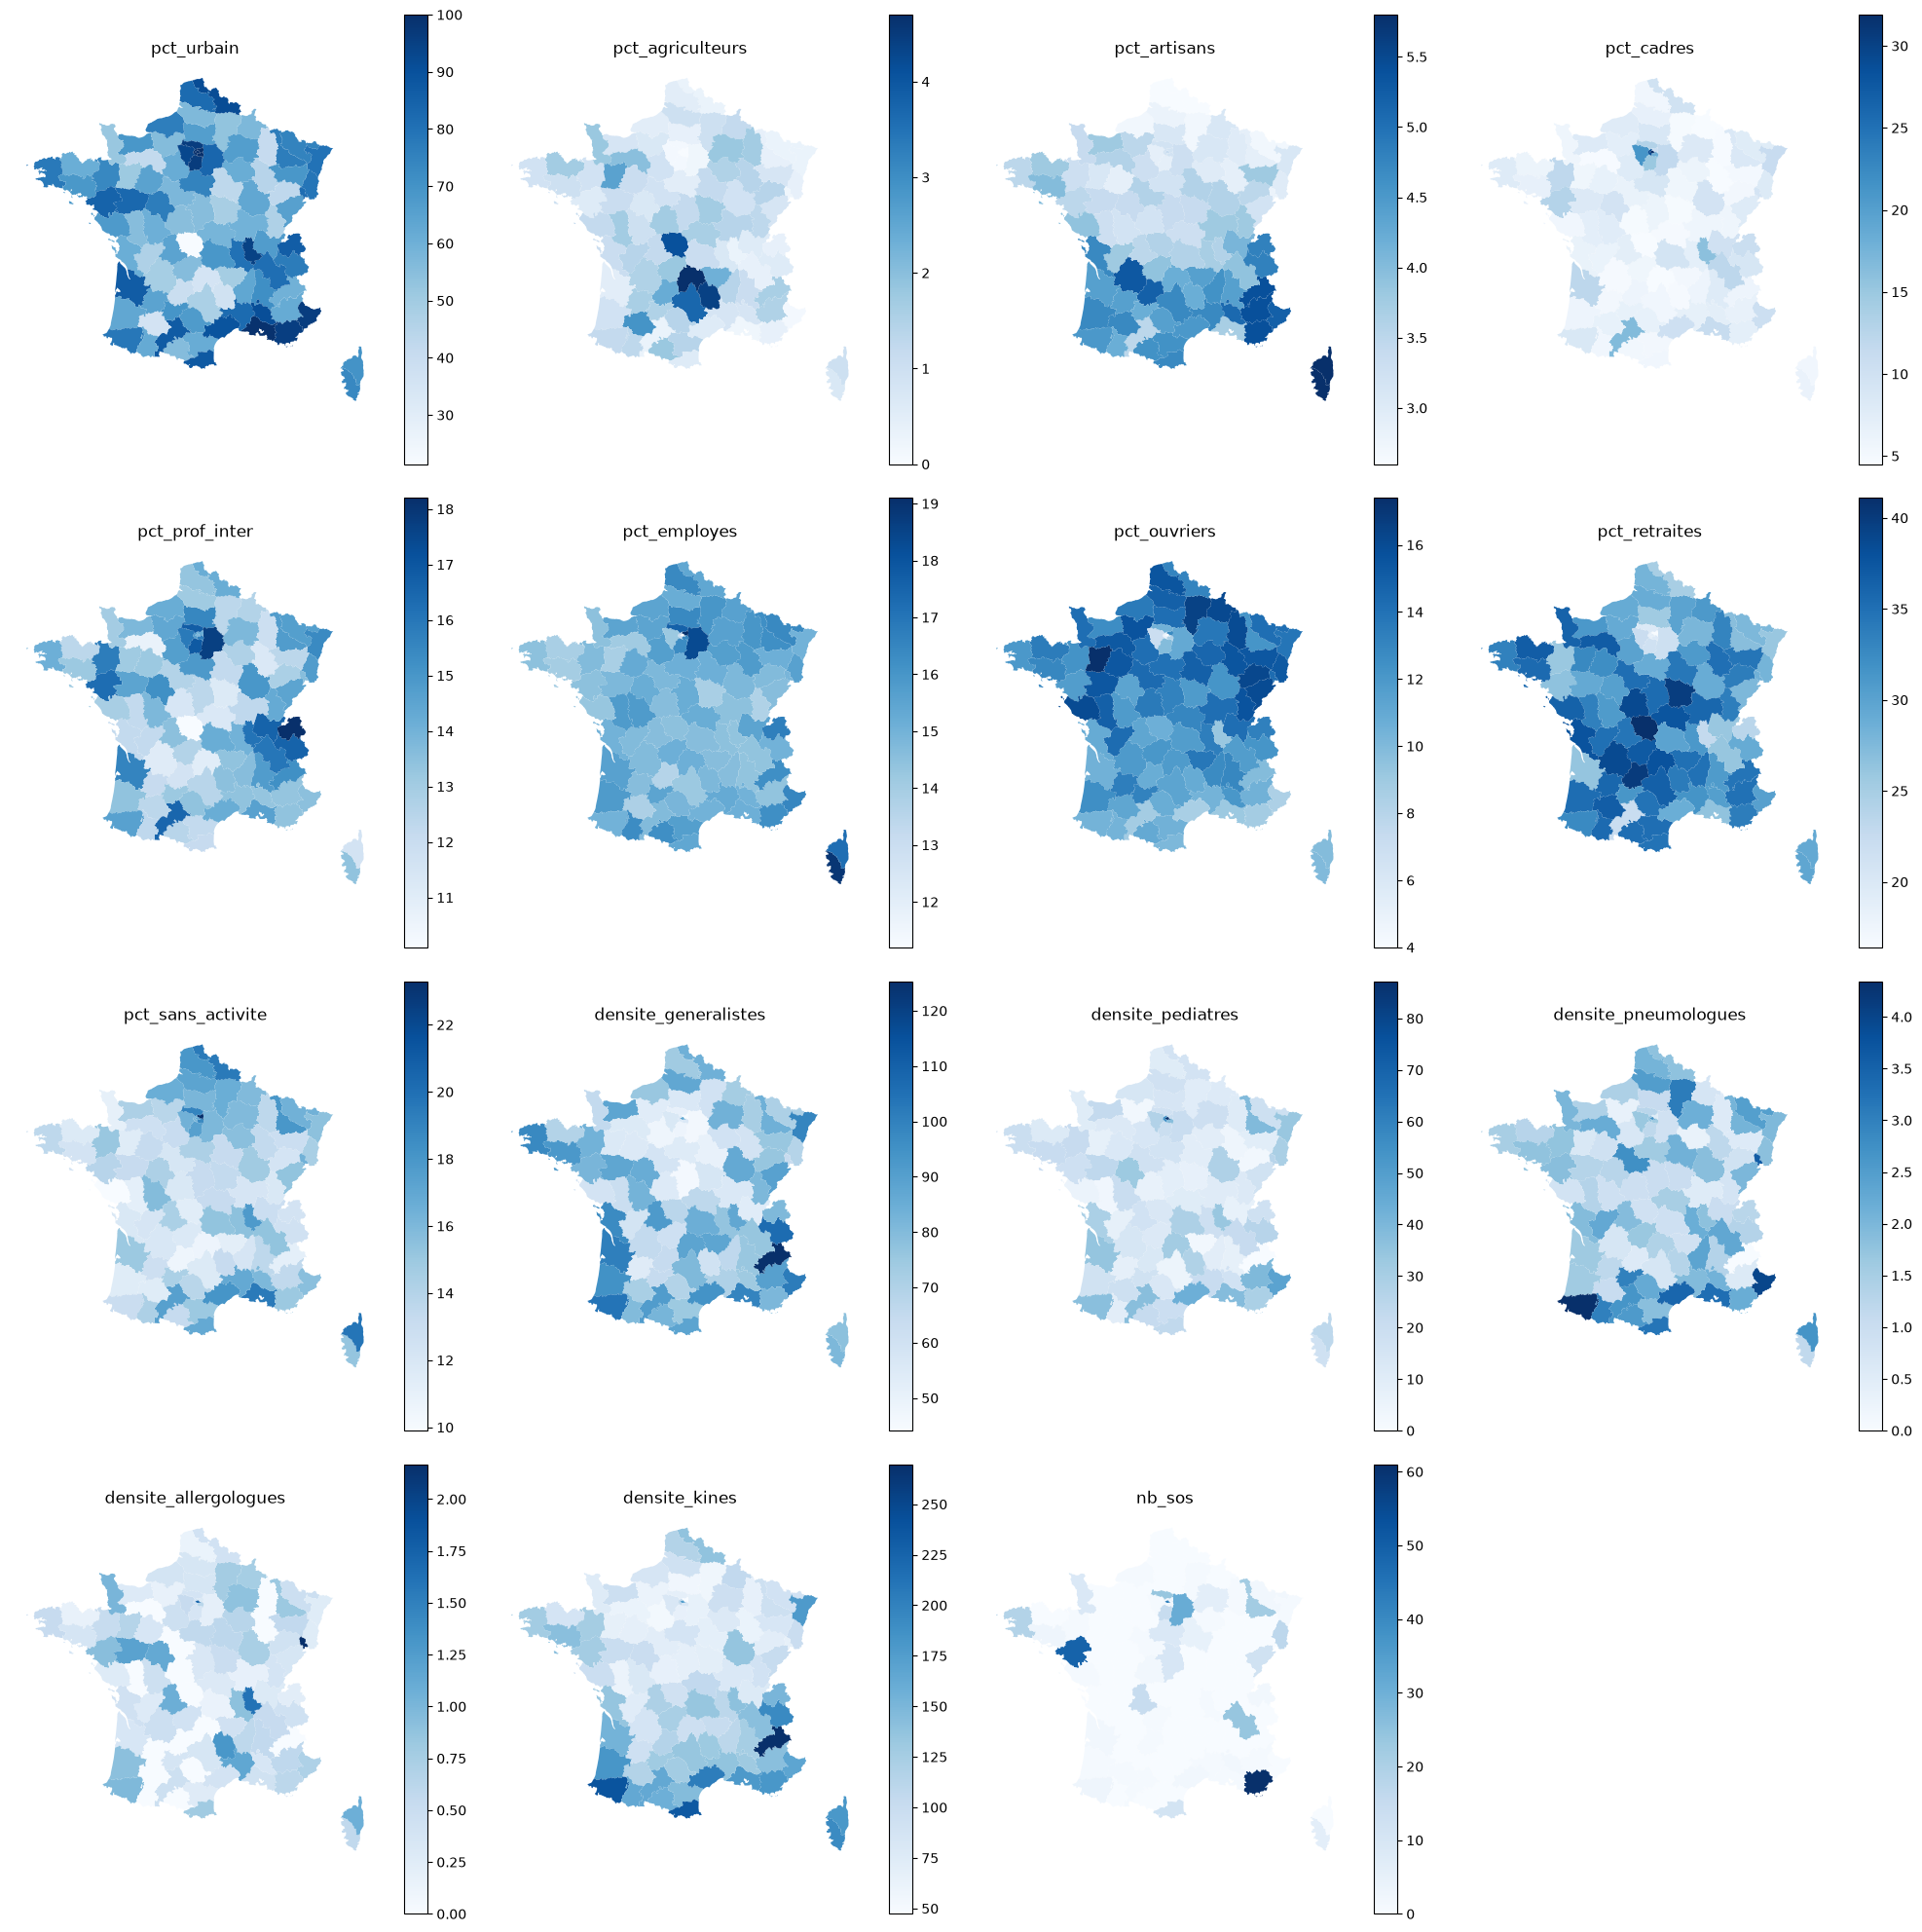

In [3]:
#  adresse internet du fond de carte (contours des 96 départements)
lien = 'https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson'
carte = gpd.read_file(lien)


# contrôle : taille et premières lignes du fichier de carte
print(carte.shape)
print(carte.head())

# renommer 'code' en 'code_dep', pour avoir le même nom que dans socio
carte = carte.rename(columns={'code': 'code_dep'})
#coller nos donées (socio) au contour des départements (carte)
carte = pd.merge(carte, socio, on='code_dep')

# contrôle : nom (carte) et nom_dep (Ameli) = même département
print(carte[['code_dep', 'nom', 'nom_dep']].head(10))

variables = ['pct_urbain', 'pct_agriculteurs', 'pct_artisans', 'pct_cadres',
             'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites',
             'pct_sans_activite', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
             'densite_allergologues', 'densite_kines', 'nb_sos']

plt.figure(figsize=(20, 20))
for i in range(15):
    ax = plt.subplot(4, 4, i + 1)
    carte.plot(column=variables[i], cmap='Blues', legend=True, ax=ax)
    ax.set_title(variables[i])
    ax.axis('off')
plt.tight_layout()
plt.show()


Unités : les colonnes pct_ sont des pourcentages (pct_urbain = % des habitants vivant en ville, les autres = % des 15 ans ou plus). Les colonnes densite_ sont pour 100 000 habitants (pour 100 000 enfants de 0 à 19 ans pour les pédiatres). nb_sos est un nombre de médecins.Les cartes montrent les 96 départements de métropole. Les DROM ne sont pas dessinés mais restent dans le tableau socio (Mayotte n'y est pas car elle manque dans le fichier CSP).

**Conclusion** 
Ce qui ressort des cartes :

- Une opposition ville / campagne : les départements urbains sont en Île-de-France, dans le Nord, autour de Lyon et sur la côte méditerranéenne. Le centre est rural, avec plus de retraités et d'agriculteurs.

- Le nord et l'est ont plus d'ouvriers et de personnes sans activité.

- Les cadres sont presque uniquement en Île-de-France.

- Le sud a plus d'artisans et commerçants, et aussi plus de soignants : généralistes, kinés et pneumologues

- Les pédiatres et les allergologues sont rares : les cartes sont presque uniformes, seules quelques grandes villes ressortent.

- Pour SOS Médecins, seuls quelques départements ressortent. Mais attention le chiffre est incomplet.


## 3. Contrôles avant la modélisation

### 3.1 Corrélations entre toutes les variables
On calcule la corrélation de Pearson entre toutes les variables, sur les 96 départements de métropole. Si |r| ≥ 0,8, on garde une seule des deux variables. À ce niveau, deux variables partagent près des 2/3 de leur information (r² = 0,64).

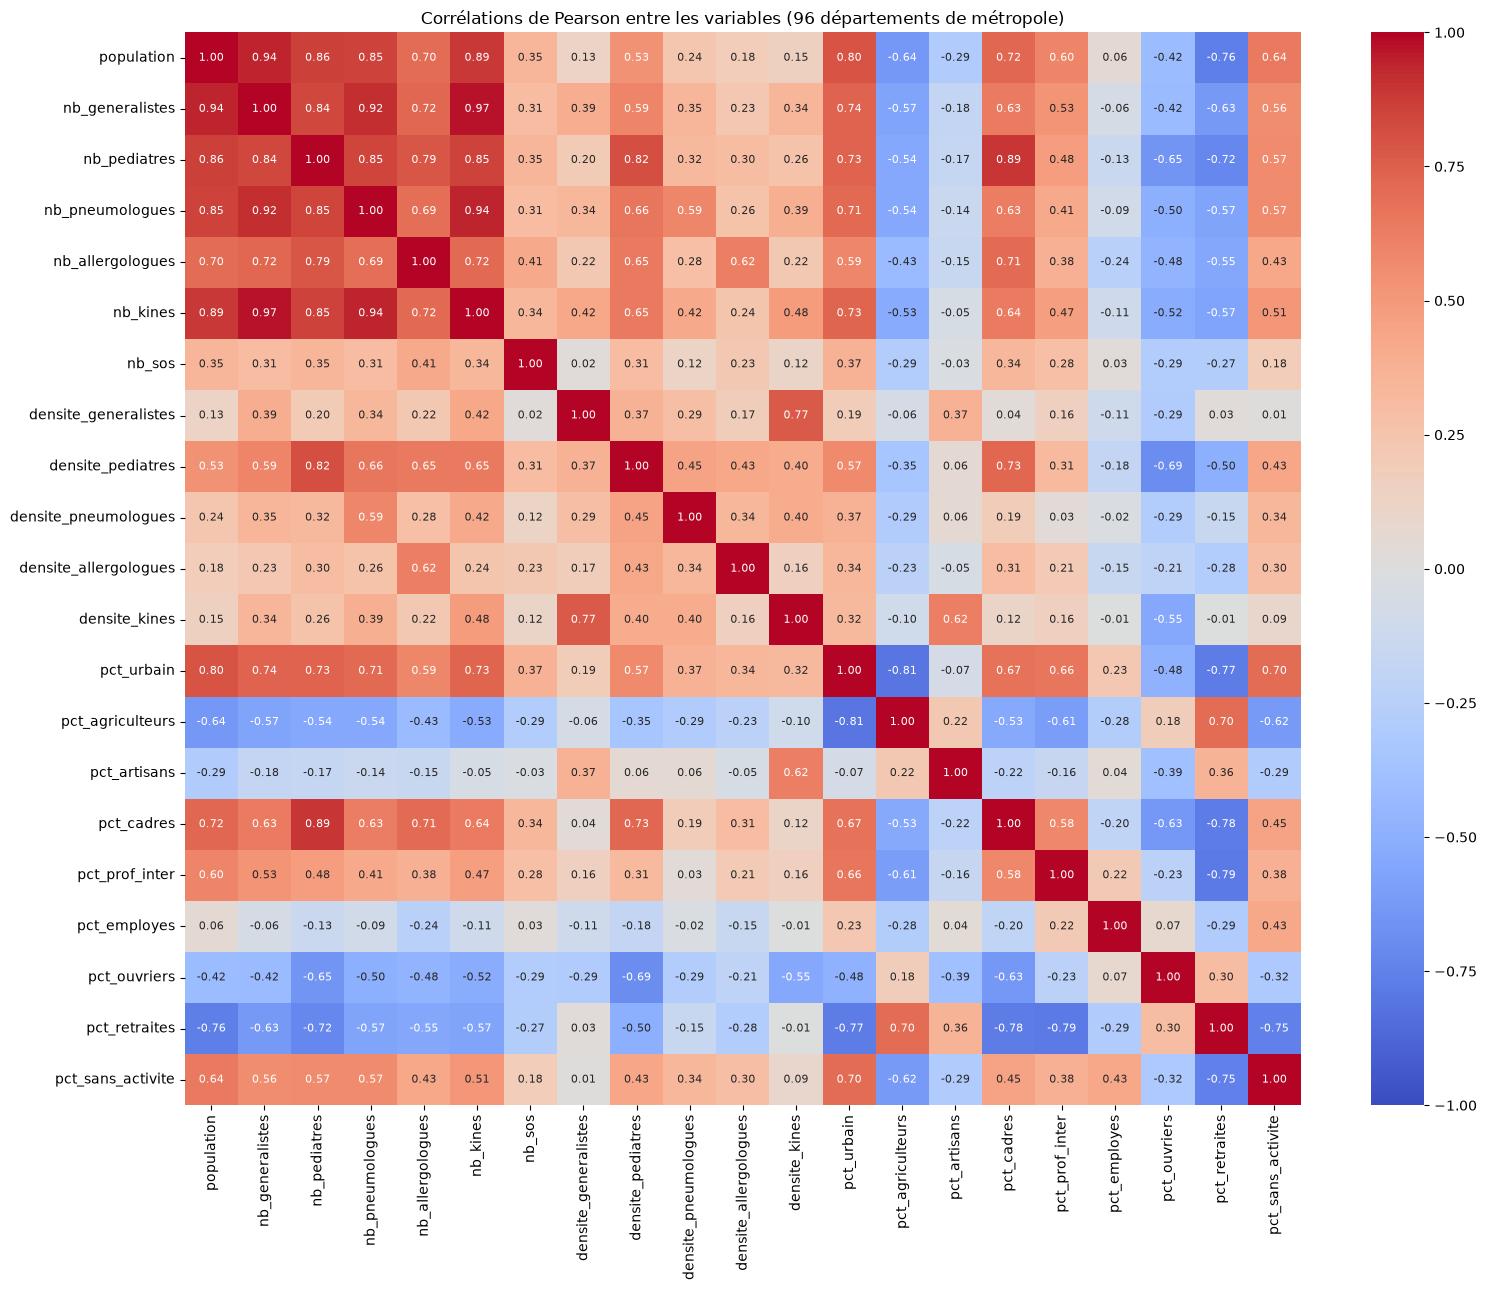

In [4]:
import seaborn as sns
from scipy.stats import pearsonr

# on travaille sur la métropole (96 départements)
metro = socio[socio['est_drom'] == False]

# toutes les variables chiffrées
variables = ['population', 'nb_generalistes', 'nb_pediatres', 'nb_pneumologues', 'nb_allergologues',
             'nb_kines', 'nb_sos', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
             'densite_allergologues', 'densite_kines', 'pct_urbain', 'pct_agriculteurs', 'pct_artisans',
             'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite']

# matrice de corrélation (21 x 21)
correlations = metro[variables].corr()

# heatmap : rouge = les deux montent ensemble, bleu = l'une monte quand l'autre baisse
plt.figure(figsize=(16, 13))
sns.heatmap(correlations, annot=True, fmt='.2f', annot_kws={'size': 8}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Corrélations de Pearson entre les variables (96 départements de métropole)')
plt.tight_layout()
plt.show()

### 3.2 Conclusion



- Un département avec beaucoup d’habitants a forcément beaucoup de médecins, juste parce qu’il est grand.Alors que la densité mesure directment l'accès aux soins.

- Population et part urbaine ont r = 0,8. Les départements les plus peuplés sont aussi les plus urbains (Nord, Paris...). La population est donc en grande partie redondante avec la part urbaine. Privilégier la part urbaine plutôt que la population: c'est un pourcentage, qui ne dépend pas de la taille du département

- pct_agriculteurs et pct_urbain ont r = -0,81 : c'est une corrélation négative, les deux varient en sens inverse. Plus un département est urbain, moins il y a d'agriculteurs. Les agriculteurs mesurent donc surtout le côté rural du département, ce que la part urbaine dit déjà.

- Les départements avec beaucoup de retraités sont plutôt ruraux, avec peu de cadres. Les retraités sont une population fragile pour les maladies respiratoires, donc on les garde.

- les 8 CSP font 100 % à elles toutes. Si une catégorie monte, les autres baissent forcément. C'est pour ça qu'on voit beaucoup de bleu entre les CSP : corrélations pas forcément la réalité.


Conclusion des contrôles:

On garde 96 départements (France métropolitaine) et 14 variables :
- la part urbaine
- 8 catégories socio-professionnelles : artisans, cadres, professions intermédiaires, employés, ouvriers, retraités, sans activité et agriculteurs: ils sont exposés aux pesticides, une information que l'unité urbaine ne donne pas.
- 5 densités de professionnels : généralistes, pédiatres, pneumologues, allergologues, kinés
- la présence de SOS Médecins (oui / non)

On retire :
- la population et les nombres de professionnels mesurent surtout la taille du département, pas l'accès aux soins. Il faut utiliser les densités qui evitent l'effet de taille des départements. Pour SOS Médecins, on garde seulement oui / non (car pas présents dans tous les départements,et certaines données manquantes pour mes collègues dans mes souvenirs).


- les DROM:
  - valeurs très différentes de la métropole + beaucoup de NA, et DROM absents dans certaines données: risque de biaiser les résultats de notre modèle
  - climat tropical saisonnalité des maladies respiratoires n'est pas la même qu'en métropole
  - 5 départements, le modèle ne pourrait pas apprendre leur fonctionnement à part.



### 3.3 Enregistrement

Deux fichiers sont enregistrés :
- socio_eco_dep.csv : version complète (100 départements, toutes les colonnes), au cas où le groupe change de choix ;
- socio_eco_dep_modele.csv : version pour le modèle (96 départements de métropole, 14 variables).

In [5]:
# Version complète : 100 départements avec les DROM, et les 25 colonnes, dont la population et les nb_.
socio = socio.rename(columns={'code_dep': 'code_dept'})
socio.to_csv('../data/processed/socio_eco_dep.csv', index=False)

In [6]:
# variables gardées pour notre modèle 
gardees = ['code_dep', 'nom_dep', 'pct_urbain',
           'pct_artisans', 'pct_cadres', 'pct_prof_inter',
           'pct_employes', 'pct_ouvriers', 'pct_retraites',
           'pct_sans_activite','pct_agriculteurs',
           'densite_generalistes', 'densite_pediatres',
           'densite_pneumologues', 'densite_allergologues',
           'densite_kines', 'sos_present']

# métropole: colonnes gardées
socio_modele = metro[gardees]

# contrôle : 96 lignes, 16 colonnes (code, nom + 14 variables)
print(socio_modele.shape)

# version choisie pour le modèle : 96 départements et 14 variables.
socio_modele = socio_modele.rename(columns={'code_dep': 'code_dept'})
socio_modele.to_csv('../data/processed/socio_eco_dep_modele.csv', index=False)

(96, 17)


Au niveau de la concordance des  années :
- Catégories Socio Professionels : le recensement 2022 est construit avec des enquêtes de 2020 à 2024, il couvre donc la période étudiée.
- Unités urbaines : le zonage INSEE 2020 (population 2017) est le zonage officiel sur toute la période 2021-2024, il n'est mis à jour que tous les 10 ans (source : insee.fr/fr/statistiques/4806684).
- Ameli 2024 : à vérifier en comparant avec Ameli 2021. 

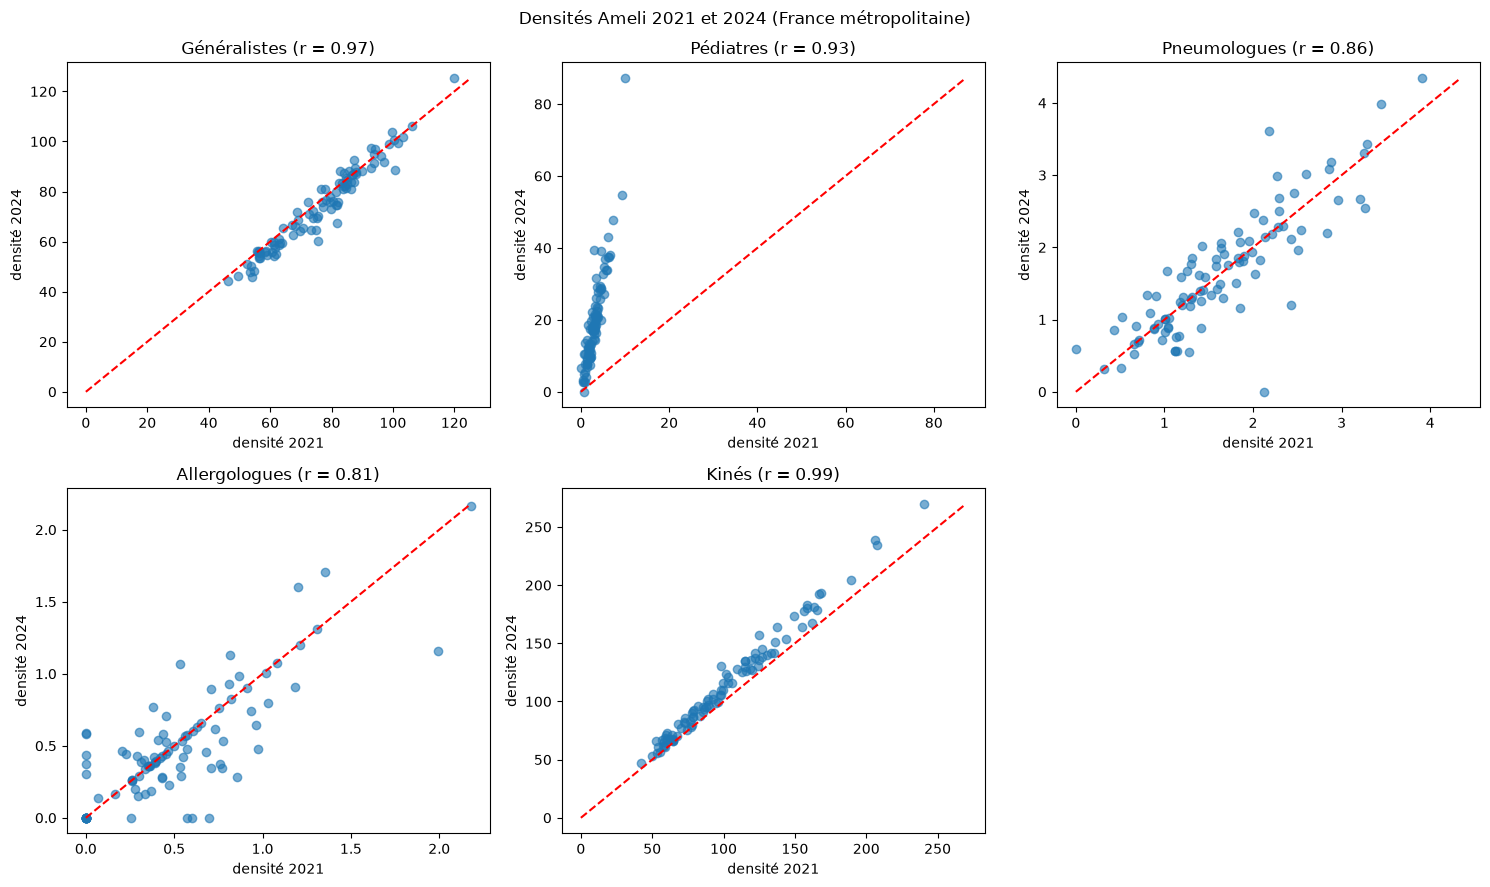

In [7]:
a21 = pd.read_csv('../data/processed/ameli_2021_propre.csv', dtype={'code_dep': str})
a24 = pd.read_csv('../data/processed/ameli_2024_propre.csv', dtype={'code_dep': str})

# les 2 années merge
annees = pd.merge(a21, a24, on='code_dep', suffixes=('_21', '_24'))

# métropole seulement
annees = annees[annees['est_drom_24'] == False]

densites = ['densite_generalistes', 'densite_pediatres',
            'densite_pneumologues', 'densite_allergologues',
            'densite_kines']
titres = ['Généralistes', 'Pédiatres', 'Pneumologues',
          'Allergologues', 'Kinés']

plt.figure(figsize=(15, 9))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    x = annees[densites[i] + '_21']
    y = annees[densites[i] + '_24']
    # un point = un département
    plt.scatter(x, y, alpha=0.6)
    # ligne rouge : même valeur en 2021 et en 2024
    maxi = max(x.max(), y.max())
    plt.plot([0, maxi], [0, maxi], color='red', linestyle='--')
    # r : Est-ce que les départements conservent le même classement ?
    r = x.corr(y)
    plt.title(titres[i] + ' (r = ' + str(round(r, 2)) + ')')
    plt.xlabel('densité 2021')
    plt.ylabel('densité 2024')

plt.suptitle('Densités Ameli 2021 et 2024 (France métropolitaine)')
plt.tight_layout()
plt.show()

Pour comparer les deux années, chaque département est placé selon sa densité en 2021 (horizontal) et en 2024 (vertical). Si les données n'ont pas changé, les points se rapproche de la ligne rouge.

- Généralistes (r = 0,97) et kinés (r = 0,99) identique. Les kinés augmentent un peu partout, mais les départements gardent le même classement.
- Pédiatres (r = 0,93) : Ameli a changé de calcul (toute la population en 2021, uniquement 0-19 ans en 2024), d'où les valeurs plus hautes en 2024. Le classement des départements reste le même.
- Pneumologues (r = 0,86) et allergologues (r = 0,81) : moins stables, car peu nombreux. 

Utiliser Ameli 2024 pour la période 2021-2024 est donc OK. Attention à être vigilant pour les densités de pneumologues et d'allergologues.